### scipy: Analysis - Übungen

**scipy** (*Scientific Python*) baut auf numpy auf und enthält fertige Verfahren für die Mathematik und die Naturwissenschaften.
In diesem Notebook geht es um Aufgaben aus der **Analysis**: Nullstellen und Schnittpunkte bestimmen, Gleichungen lösen,
Hoch- und Tiefpunkte finden, Extremwertaufgaben lösen und Integrale berechnen. Statt mit Formeln rechnet scipy **numerisch**:
Es nähert die Lösung Schritt für Schritt an, bis sie sehr genau ist. Damit lassen sich auch Gleichungen lösen, für die es keine Formel gibt.

Die Reihe hat vier Notebooks:

1. **Analysis**: Nullstellen, Gleichungen, Extremstellen, Integrale (dieses Notebook)
2. Messdaten auswerten: Interpolation, Ausgleichskurven, Spitzen finden
3. Stochastik: Verteilungen und Hypothesentests
4. Anwendungen: Änderungsraten und Modelle, lineare Optimierung, Abstände

Vorausgesetzt werden die Notebooks *Funktionen*, *numpy: Grundlagen*, *numpy: Mathematik* und *matplotlib: Grundlagen*
(`plt.fill_between()` aus *matplotlib: Diagrammtypen* wird in den Aufgaben kurz beschrieben).

Jeder Abschnitt beginnt mit kurzen Erklärungen und Beispielen. Führe die Beispiele aus und probiere sie ruhig ein wenig aus.
Danach folgen viele kleine Übungen. Wenn etwas vorgegeben ist, steht es schon in der Codezelle.

Beim ersten `import scipy` lädt der Browser das Paket nach. Das dauert ein paar Sekunden.
Weil scipy numerisch rechnet, werden die Ergebnisse in den Aufgaben immer gerundet.

Unter den Aufgaben kannst du jeweils die Lösung aufklappen. Versuche es aber immer zuerst selbst!
Bei den Aufgaben „Was wird ausgegeben?“ überlegst du zuerst, führst dann die Zelle aus und vergleichst.
Die aufklappbare Lösung erklärt dort, wie die Ausgabe zustande kommt.

## 1. Nullstellen

#### Funktionen als Argument

Die Verfahren von scipy bekommen die mathematische Funktion als **Python-Funktion**: Man schreibt sie mit `def` und übergibt
den Namen **ohne Klammern**. scipy ruft die Funktion dann selbst mit vielen verschiedenen Werten auf.

Die Funktion sollte mit numpy-Funktionen rechnen (`np.exp()`, `np.sin()`, `np.sqrt()` usw.), dann funktioniert sie auch für Arrays.
Das braucht man zum Zeichnen.

In [ ]:
import numpy as np


def f(x):
    return x ** 2 - 2


def wertetabelle(funktion, werte):
    for x in werte:
        print(x, funktion(x))


wertetabelle(f, [0, 1, 2])
print(f(np.array([0, 1, 2])))

#### `optimize.brentq()`

Das Modul `scipy.optimize` enthält Verfahren zum Lösen von Gleichungen und zum Optimieren.
`optimize.brentq(f, a, b)` sucht eine **Nullstelle** von `f` im Intervall von `a` bis `b`.
Dafür muss `f` an den Rändern verschiedene Vorzeichen haben (ein **Vorzeichenwechsel**), dann liegt dazwischen sicher eine Nullstelle.

Das Ergebnis ist eine Kommazahl, die bis auf etwa 12 Stellen genau ist. Zum Ausgeben rundet man sie mit `round()`.

In [ ]:
from scipy import optimize


def f(x):
    return x ** 2 - 2


x0 = optimize.brentq(f, 0, 2)
print(x0)
print(round(x0, 4))

#### Kein Vorzeichenwechsel

Haben `f(a)` und `f(b)` dasselbe Vorzeichen, bricht `brentq()` mit einem `ValueError` ab.
Das Intervall muss dann so gewählt werden, dass genau eine Nullstelle darin liegt.

In [ ]:
from scipy import optimize


def f(x):
    return x ** 2 - 2


print(f(-2), f(2))
optimize.brentq(f, -2, 2)

#### Mehrere Nullstellen finden

Hat eine Funktion mehrere Nullstellen, sucht man zuerst mit einer **Wertetabelle** die Stellen, an denen sich das Vorzeichen ändert,
und ruft dann für jedes dieser Intervalle `brentq()` auf. Ein Vorzeichenwechsel zwischen `x[i]` und `x[i + 1]` liegt vor,
wenn `f(x[i]) * f(x[i + 1]) < 0` ist.

In [ ]:
import numpy as np
from scipy import optimize


def f(x):
    return x ** 3 - 6 * x ** 2 + 4 * x + 4


x = np.arange(-3, 7)
y = f(x)
for i in range(len(x) - 1):
    if y[i] * y[i + 1] < 0:
        print(x[i], x[i + 1], round(optimize.brentq(f, x[i], x[i + 1]), 4))

#### Aufgabe 1.1

Bestimme die Nullstelle von `f(x) = x³ + x - 5` im Intervall von 1 bis 2. Runde auf 4 Nachkommastellen.

**Erwartete Ausgabe:**
```
1.516
```

In [ ]:
from scipy import optimize
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
from scipy import optimize


def f(x):
    return x ** 3 + x - 5


print(round(optimize.brentq(f, 1, 2), 4))
```

</details>

#### Aufgabe 1.2

Bestimme die positive Nullstelle von `f(x) = x² - 7` und vergleiche mit `np.sqrt(7)`. Gib beides auf 6 Nachkommastellen gerundet aus.

**Erwartete Ausgabe:**
```
2.645751
2.645751
```

In [ ]:
import numpy as np
from scipy import optimize
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import numpy as np
from scipy import optimize


def f(x):
    return x ** 2 - 7


print(round(optimize.brentq(f, 0, 3), 6))
print(round(np.sqrt(7), 6))
```

</details>

#### Aufgabe 1.3

Prüfe für die Funktion `f(x) = x³ - 2x - 5`, ob in den Intervallen [0, 1], [1, 2], [2, 3] ein Vorzeichenwechsel vorliegt.
Gib für jedes Intervall die Grenzen und `True` oder `False` aus.

**Erwartete Ausgabe:**
```
0 1 False
1 2 False
2 3 True
```

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
def f(x):
    return x ** 3 - 2 * x - 5


for a, b in [(0, 1), (1, 2), (2, 3)]:
    print(a, b, f(a) * f(b) < 0)
```

</details>

#### Aufgabe 1.4

Bestimme die Nullstelle von `f(x) = x³ - 2x - 5` aus der vorigen Aufgabe auf 5 Nachkommastellen.

**Erwartete Ausgabe:**
```
2.09455
```

In [ ]:
from scipy import optimize
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
from scipy import optimize


def f(x):
    return x ** 3 - 2 * x - 5


print(round(optimize.brentq(f, 2, 3), 5))
```

</details>

#### Aufgabe 1.5

Bestimme die Nullstelle von `f(x) = e^x - 4` (`np.exp()`) im Intervall von 0 bis 2 und vergleiche mit `np.log(4)`.
Gib beides auf 6 Nachkommastellen aus.

**Erwartete Ausgabe:**
```
1.386294
1.386294
```

In [ ]:
import numpy as np
from scipy import optimize
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import numpy as np
from scipy import optimize


def f(x):
    return np.exp(x) - 4


print(round(optimize.brentq(f, 0, 2), 6))
print(round(np.log(4), 6))
```

</details>

#### Aufgabe 1.6

Die Funktion `f(x) = cos(x) - x` hat genau eine Nullstelle. Bestimme sie auf 4 Nachkommastellen.
Wähle das Intervall mit Hilfe von `f(0)` und `f(1)`.

**Erwartete Ausgabe:**
```
1.0 -0.4597
0.7391
```

In [ ]:
import numpy as np
from scipy import optimize
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import numpy as np
from scipy import optimize


def f(x):
    return np.cos(x) - x


print(f(0), round(f(1), 4))
print(round(optimize.brentq(f, 0, 1), 4))
```

</details>

#### Aufgabe 1.7

Bestimme alle drei Nullstellen von `f(x) = x³ - 4x + 1`. Suche die Vorzeichenwechsel mit einer Wertetabelle für die ganzen Zahlen
von -3 bis 3 und gib jede Nullstelle auf 4 Nachkommastellen aus.

**Erwartete Ausgabe:**
```
-2.1149
0.2541
1.8608
```

In [ ]:
import numpy as np
from scipy import optimize
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import numpy as np
from scipy import optimize


def f(x):
    return x ** 3 - 4 * x + 1


x = np.arange(-3, 4)
y = f(x)
for i in range(len(x) - 1):
    if y[i] * y[i + 1] < 0:
        print(round(optimize.brentq(f, x[i], x[i + 1]), 4))
```

</details>

#### Aufgabe 1.8

Schreibe eine Funktion `nullstellen(f, start, ende)`, die die Nullstellen von `f` zwischen den ganzen Zahlen `start` und `ende`
als Liste von auf 4 Stellen gerundeten Zahlen zurückgibt (Vorzeichenwechsel zwischen benachbarten ganzen Zahlen).
Teste sie mit `g(x) = x⁴ - 5x² + 3` zwischen -3 und 3.

**Erwartete Ausgabe:**
```
[-2.0743, -0.835, 0.835, 2.0743]
```

In [ ]:
import numpy as np
from scipy import optimize
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import numpy as np
from scipy import optimize


def nullstellen(f, start, ende):
    x = np.arange(start, ende + 1)
    y = f(x)
    ergebnis = []
    for i in range(len(x) - 1):
        if y[i] * y[i + 1] < 0:
            ergebnis.append(round(optimize.brentq(f, x[i], x[i + 1]), 4))
    return ergebnis


def g(x):
    return x ** 4 - 5 * x ** 2 + 3


print(nullstellen(g, -3, 3))
```

</details>

#### Aufgabe 1.9

Zeichne den Graphen von `f(x) = x³ - 4x + 1` für x von -3 bis 3 (200 Punkte) mit einer schwarzen x-Achse (`plt.axhline(0, color='black')`)
und markiere die drei Nullstellen als rote Punkte (`'ro'`). Bestimme die Nullstellen mit `brentq()` in den Intervallen [-3, -2], [0, 1] und [1, 2].

**Erwartete Ausgabe:**

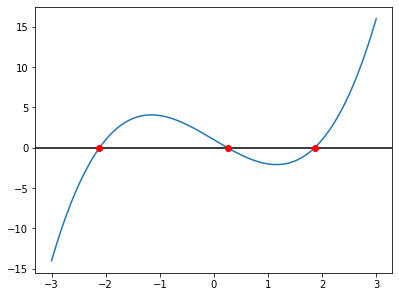

In [ ]:
import numpy as np
from scipy import optimize
import matplotlib.pyplot as plt
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import numpy as np
from scipy import optimize
import matplotlib.pyplot as plt


def f(x):
    return x ** 3 - 4 * x + 1


x = np.linspace(-3, 3, 200)
plt.plot(x, f(x))
plt.axhline(0, color='black')
for a, b in [(-3, -2), (0, 1), (1, 2)]:
    x0 = optimize.brentq(f, a, b)
    plt.plot(x0, 0, 'ro')
plt.show()
```

</details>

#### Aufgabe 1.10

Was wird ausgegeben? Überlege zuerst, was ausgegeben wird. Führe dann die Zelle aus und vergleiche.

In [ ]:
from scipy import optimize


def f(x):
    return 2 * x - 3


print(f(0), f(5))
print(round(optimize.brentq(f, 0, 5), 4))

<details>
<summary>Lösung anzeigen (erst selbst überlegen!)</summary>

**Ausgabe:**
```
-3 7
1.5
```

- `f(0) = -3` und `f(5) = 7` haben verschiedene Vorzeichen, also liegt dazwischen eine Nullstelle.
- `2x - 3 = 0` gilt für `x = 1.5`. `brentq()` findet das bis auf winzige Rundungsfehler, gerundet `1.5`.

</details>

#### Aufgabe 1.11

Was wird ausgegeben? Überlege zuerst, was ausgegeben wird. Führe dann die Zelle aus und vergleiche.

In [ ]:
from scipy import optimize


def f(x):
    return x ** 2 + 1


optimize.brentq(f, -1, 1)

<details>
<summary>Lösung anzeigen (erst selbst überlegen!)</summary>

**Fehler:** `ValueError`

`f(-1) = 2` und `f(1) = 2` haben dasselbe Vorzeichen. `brentq()` braucht einen Vorzeichenwechsel und bricht mit
einem `ValueError` ab. (`x² + 1` hat übrigens gar keine Nullstelle.)

</details>

## 2. Schnittpunkte und Gleichungen

#### Gleichungen umformen

Eine Gleichung wie `e^x = 3x` löst man, indem man alles auf eine Seite bringt: `e^x - 3x = 0`.
Die Lösungen sind dann die Nullstellen von `h(x) = e^x - 3x`.

Genauso findet man die **Schnittstellen** zweier Graphen `f` und `g`: Es sind die Nullstellen der Differenzfunktion `h(x) = f(x) - g(x)`.
Den Schnittpunkt erhält man, wenn man die Schnittstelle in `f` (oder `g`) einsetzt.

In [ ]:
import numpy as np
from scipy import optimize


def f(x):
    return np.exp(x)


def g(x):
    return 3 * x


def h(x):
    return f(x) - g(x)


for a, b in [(0, 1), (1, 2)]:
    xs = optimize.brentq(h, a, b)
    print(round(xs, 4), round(f(xs), 4))

#### Gleichungssysteme mit `optimize.fsolve()`

Für **mehrere Gleichungen mit mehreren Unbekannten**, die nicht linear sind, gibt es `optimize.fsolve(gleichungen, start)`.

- Die Funktion `gleichungen(v)` bekommt die Unbekannten als Array `v` (z. B. `x, y = v`) und gibt eine Liste zurück:
  für jede Gleichung die linke Seite minus die rechte Seite.
- `start` ist ein **Startwert**, z. B. `[1, 1]`. `fsolve()` sucht die Lösung in seiner Nähe.
  Hat das System mehrere Lösungen, findet man sie mit verschiedenen Startwerten.
- Das Ergebnis ist ein Array mit den Werten der Unbekannten.

Beispiel: Schnittpunkte des Kreises `x² + y² = 25` mit der Geraden `y = x + 1`.

In [ ]:
import numpy as np
from scipy import optimize


def gleichungen(v):
    x, y = v
    return [x ** 2 + y ** 2 - 25, y - (x + 1)]


print(np.round(optimize.fsolve(gleichungen, [1, 1]), 4))
print(np.round(optimize.fsolve(gleichungen, [-5, -5]), 4))

#### Aufgabe 2.1

Löse die Gleichung `x³ = x + 1` im Intervall von 1 bis 2. Gib die Lösung auf 4 Nachkommastellen aus.

**Erwartete Ausgabe:**
```
1.3247
```

In [ ]:
from scipy import optimize
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
from scipy import optimize


def h(x):
    return x ** 3 - (x + 1)


print(round(optimize.brentq(h, 1, 2), 4))
```

</details>

#### Aufgabe 2.2

Bestimme den Schnittpunkt der Graphen von `f(x) = √x` und `g(x) = 3 - x` im Intervall von 0 bis 3.
Gib x- und y-Koordinate auf 4 Nachkommastellen aus.

**Erwartete Ausgabe:**
```
1.6972 1.3028
```

In [ ]:
import numpy as np
from scipy import optimize
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import numpy as np
from scipy import optimize


def f(x):
    return np.sqrt(x)


def g(x):
    return 3 - x


def h(x):
    return f(x) - g(x)


xs = optimize.brentq(h, 0, 3)
print(round(xs, 4), round(f(xs), 4))
```

</details>

#### Aufgabe 2.3

Für welches `x` gilt `2^x = 10`? Bestimme die Lösung mit `brentq()` im Intervall von 0 bis 5 und zum Vergleich mit `np.log2(10)`.
Gib beides auf 6 Nachkommastellen aus.

**Erwartete Ausgabe:**
```
3.321928
3.321928
```

In [ ]:
import numpy as np
from scipy import optimize
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import numpy as np
from scipy import optimize


def h(x):
    return 2 ** x - 10


print(round(optimize.brentq(h, 0, 5), 6))
print(round(np.log2(10), 6))
```

</details>

#### Aufgabe 2.4

Die Graphen von `f(x) = x²` und `g(x) = 2^x` schneiden sich dreimal. Gib die drei Schnittstellen aus.
Die Intervalle sind [-1, 0], [1, 3] und [3, 5]. Runde auf 4 Nachkommastellen.

**Erwartete Ausgabe:**
```
-0.7667
2.0
4.0
```

In [ ]:
from scipy import optimize
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
from scipy import optimize


def h(x):
    return x ** 2 - 2 ** x


for a, b in [(-1, 0), (1, 3), (3, 5)]:
    print(round(optimize.brentq(h, a, b), 4))
```

</details>

#### Aufgabe 2.5

Ein Kapital von 1000 € wird mit 3 % pro Jahr verzinst: `K(t) = 1000 · 1.03^t`. Nach wie vielen Jahren ist es auf 1500 € angewachsen?
Löse `K(t) = 1500` mit `brentq()` im Intervall von 0 bis 50 und runde auf 2 Nachkommastellen.

**Erwartete Ausgabe:**
```
13.72
```

In [ ]:
from scipy import optimize
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
from scipy import optimize


def h(t):
    return 1000 * 1.03 ** t - 1500


print(round(optimize.brentq(h, 0, 50), 2))
```

</details>

#### Aufgabe 2.6

Zeichne die Graphen von `f(x) = cos(x)` (blau) und `g(x) = x / 2` (grün) für x von -3 bis 3 (200 Punkte) und markiere ihren
Schnittpunkt als roten Punkt. Er liegt im Intervall [0, 2]. Gib außerdem die Koordinaten auf 4 Nachkommastellen aus.

**Erwartete Ausgabe:**
```
1.0299 0.5149
```

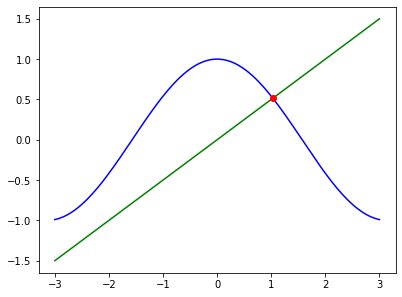

In [ ]:
import numpy as np
from scipy import optimize
import matplotlib.pyplot as plt
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import numpy as np
from scipy import optimize
import matplotlib.pyplot as plt


def f(x):
    return np.cos(x)


def g(x):
    return x / 2


def h(x):
    return f(x) - g(x)


xs = optimize.brentq(h, 0, 2)
print(round(xs, 4), round(f(xs), 4))
x = np.linspace(-3, 3, 200)
plt.plot(x, f(x), color='blue')
plt.plot(x, g(x), color='green')
plt.plot(xs, f(xs), 'ro')
plt.show()
```

</details>

#### Aufgabe 2.7

Bestimme mit `fsolve()` die beiden Schnittpunkte des Kreises `x² + y² = 10` mit der Parabel `y = x²`.
Benutze die Startwerte `[1, 1]` und `[-1, 1]` und gib die Ergebnisse auf 4 Nachkommastellen aus.

**Erwartete Ausgabe:**
```
[1.6436 2.7016]
[-1.6436  2.7016]
```

In [ ]:
import numpy as np
from scipy import optimize
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import numpy as np
from scipy import optimize


def gleichungen(v):
    x, y = v
    return [x ** 2 + y ** 2 - 10, y - x ** 2]


print(np.round(optimize.fsolve(gleichungen, [1, 1]), 4))
print(np.round(optimize.fsolve(gleichungen, [-1, 1]), 4))
```

</details>

#### Aufgabe 2.8

Löse das Gleichungssystem `x · y = 6` und `x + y = 5` mit `fsolve()`. Es hat zwei Lösungen.
Finde beide mit den Startwerten `[1, 4]` und `[4, 1]` und gib sie auf 4 Nachkommastellen aus.

**Erwartete Ausgabe:**
```
[2. 3.]
[3. 2.]
```

In [ ]:
import numpy as np
from scipy import optimize
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import numpy as np
from scipy import optimize


def gleichungen(v):
    x, y = v
    return [x * y - 6, x + y - 5]


print(np.round(optimize.fsolve(gleichungen, [1, 4]), 4))
print(np.round(optimize.fsolve(gleichungen, [4, 1]), 4))
```

</details>

#### Aufgabe 2.9

Ein Rechteck hat die Fläche 12 und eine Diagonale der Länge 5. Bestimme die Seitenlängen `a` und `b` mit `fsolve()`
(Gleichungen `a · b = 12` und `a² + b² = 25`, Startwert `[4, 2]`) und gib sie auf 4 Nachkommastellen aus.

**Erwartete Ausgabe:**
```
[4. 3.]
```

In [ ]:
import numpy as np
from scipy import optimize
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import numpy as np
from scipy import optimize


def gleichungen(v):
    a, b = v
    return [a * b - 12, a ** 2 + b ** 2 - 25]


print(np.round(optimize.fsolve(gleichungen, [4, 2]), 4))
```

</details>

#### Aufgabe 2.10

Gesucht ist die Parabel `f(x) = ax² + bx + c`, die durch die Punkte (1|2), (2|3) und (3|6) geht. Stelle die drei Gleichungen
`f(1) = 2`, `f(2) = 3`, `f(3) = 6` auf, löse sie mit `fsolve()` (Startwert `[0, 0, 0]`) und gib `a`, `b` und `c` auf 4 Nachkommastellen aus.

**Erwartete Ausgabe:**
```
[ 1. -2.  3.]
```

In [ ]:
import numpy as np
from scipy import optimize
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import numpy as np
from scipy import optimize


def gleichungen(v):
    a, b, c = v
    return [a + b + c - 2, 4 * a + 2 * b + c - 3, 9 * a + 3 * b + c - 6]


print(np.round(optimize.fsolve(gleichungen, [0, 0, 0]), 4))
```

</details>

#### Aufgabe 2.11

Was wird ausgegeben? Überlege zuerst, was ausgegeben wird. Führe dann die Zelle aus und vergleiche.

In [ ]:
import numpy as np
from scipy import optimize


def gleichungen(v):
    x, y = v
    return [x + y - 3, x - y - 1]


print(np.round(optimize.fsolve(gleichungen, [0, 0]), 4))

<details>
<summary>Lösung anzeigen (erst selbst überlegen!)</summary>

**Ausgabe:**
```
[2. 1.]
```

Die Funktion beschreibt die Gleichungen `x + y = 3` und `x - y = 1`. Addiert man sie, ergibt sich `2x = 4`, also `x = 2` und `y = 1`.
`fsolve()` gibt die Lösung als Array aus: `[2. 1.]`.

</details>

## 3. Extremstellen

#### `optimize.minimize_scalar()`

`optimize.minimize_scalar(f, bounds=(a, b))` sucht die Stelle zwischen `a` und `b`, an der `f` am kleinsten ist (ein **Minimum**).
Das Ergebnis ist ein Objekt mit mehreren Angaben:

- `ergebnis.x`: die Stelle des Minimums
- `ergebnis.fun`: der Funktionswert dort (*function*)

Ohne `bounds` sucht das Verfahren irgendwo, deshalb gibt man in diesem Notebook immer einen Bereich an.

In [ ]:
from scipy import optimize


def f(x):
    return x ** 2 - 4 * x + 7


ergebnis = optimize.minimize_scalar(f, bounds=(0, 5))
print(round(ergebnis.x, 4))
print(round(ergebnis.fun, 4))

#### Maximum: das Minimum von `-f`

Es gibt kein eigenes Verfahren für das Maximum. Man sucht stattdessen das Minimum von `-f`:
Wo `-f` am kleinsten ist, ist `f` am größten. Den Funktionswert berechnet man danach mit `f` selbst.

Hat eine Funktion mehrere Hoch- oder Tiefpunkte, wählt man `bounds` so, dass nur einer darin liegt.
Liegt der kleinste Wert am **Rand** des Bereichs, gibt `minimize_scalar()` (fast) den Rand zurück.

In [ ]:
from scipy import optimize


def f(x):
    return x ** 3 - 3 * x


def minus_f(x):
    return -f(x)


hoch = optimize.minimize_scalar(minus_f, bounds=(-2, 0))
print('Hochpunkt:', round(hoch.x, 4), round(f(hoch.x), 4))
tief = optimize.minimize_scalar(f, bounds=(0, 2))
print('Tiefpunkt:', round(tief.x, 4), round(tief.fun, 4))

#### Aufgabe 3.1

Bestimme den Tiefpunkt von `f(x) = x² + 6x + 5` im Bereich von -10 bis 10. Gib beide Koordinaten auf 4 Nachkommastellen aus.

**Erwartete Ausgabe:**
```
-3.0 -4.0
```

In [ ]:
from scipy import optimize
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
from scipy import optimize


def f(x):
    return x ** 2 + 6 * x + 5


e = optimize.minimize_scalar(f, bounds=(-10, 10))
print(round(e.x, 4), round(e.fun, 4))
```

</details>

#### Aufgabe 3.2

Bestimme den Hochpunkt von `f(x) = -2x² + 8x - 3` im Bereich von 0 bis 5. Gib beide Koordinaten auf 4 Nachkommastellen aus.

**Erwartete Ausgabe:**
```
2.0 5.0
```

In [ ]:
from scipy import optimize
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
from scipy import optimize


def f(x):
    return -2 * x ** 2 + 8 * x - 3


def minus_f(x):
    return -f(x)


e = optimize.minimize_scalar(minus_f, bounds=(0, 5))
print(round(e.x, 4), round(f(e.x), 4))
```

</details>

#### Aufgabe 3.3

Die Funktion `f(x) = x³ - 6x² + 9x + 1` hat einen Hochpunkt zwischen 0 und 2 und einen Tiefpunkt zwischen 2 und 4.
Bestimme beide und gib sie wie im Beispiel aus (`Hochpunkt: ...`, `Tiefpunkt: ...`, 4 Nachkommastellen).

**Erwartete Ausgabe:**
```
Hochpunkt: 1.0 5.0
Tiefpunkt: 3.0 1.0
```

In [ ]:
from scipy import optimize
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
from scipy import optimize


def f(x):
    return x ** 3 - 6 * x ** 2 + 9 * x + 1


def minus_f(x):
    return -f(x)


hoch = optimize.minimize_scalar(minus_f, bounds=(0, 2))
print('Hochpunkt:', round(hoch.x, 4), round(f(hoch.x), 4))
tief = optimize.minimize_scalar(f, bounds=(2, 4))
print('Tiefpunkt:', round(tief.x, 4), round(tief.fun, 4))
```

</details>

#### Aufgabe 3.4

Bestimme den Hochpunkt von `f(x) = x · e^(-x)` im Bereich von 0 bis 5 (4 Nachkommastellen).

**Erwartete Ausgabe:**
```
1.0 0.3679
```

In [ ]:
import numpy as np
from scipy import optimize
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import numpy as np
from scipy import optimize


def f(x):
    return x * np.exp(-x)


def minus_f(x):
    return -f(x)


e = optimize.minimize_scalar(minus_f, bounds=(0, 5))
print(round(e.x, 4), round(f(e.x), 4))
```

</details>

#### Aufgabe 3.5

Bestimme den Tiefpunkt von `f(x) = x + 4 / x` für x zwischen 0.5 und 10 (4 Nachkommastellen).

**Erwartete Ausgabe:**
```
2.0 4.0
```

In [ ]:
from scipy import optimize
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
from scipy import optimize


def f(x):
    return x + 4 / x


e = optimize.minimize_scalar(f, bounds=(0.5, 10))
print(round(e.x, 4), round(e.fun, 4))
```

</details>

#### Aufgabe 3.6

Die Ableitung von `f(x) = x³ - 3x` ist `f'(x) = 3x² - 3`. Bestimme die Extremstellen auf zwei Wegen und gib sie auf 4 Nachkommastellen aus:
als Nullstellen von `f'` mit `brentq()` (Intervalle [-2, 0] und [0, 2]) und mit `minimize_scalar()` wie im Beispiel.

**Erwartete Ausgabe:**
```
-1.0 1.0
-1.0 1.0
```

In [ ]:
from scipy import optimize
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
from scipy import optimize


def f(x):
    return x ** 3 - 3 * x


def f_strich(x):
    return 3 * x ** 2 - 3


def minus_f(x):
    return -f(x)


print(round(optimize.brentq(f_strich, -2, 0), 4), round(optimize.brentq(f_strich, 0, 2), 4))
print(round(optimize.minimize_scalar(minus_f, bounds=(-2, 0)).x, 4), round(optimize.minimize_scalar(f, bounds=(0, 2)).x, 4))
```

</details>

#### Aufgabe 3.7

Ein Ball wird senkrecht nach oben geworfen. Seine Höhe in Metern nach `t` Sekunden ist `h(t) = 1.5 + 12t - 4.905t²`.
Wann erreicht er die größte Höhe und wie hoch ist sie? Suche im Bereich von 0 bis 3 und runde auf 2 Nachkommastellen.

**Erwartete Ausgabe:**
```
1.22 8.84
```

In [ ]:
from scipy import optimize
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
from scipy import optimize


def h(t):
    return 1.5 + 12 * t - 4.905 * t ** 2


def minus_h(t):
    return -h(t)


e = optimize.minimize_scalar(minus_h, bounds=(0, 3))
print(round(e.x, 2), round(h(e.x), 2))
```

</details>

#### Aufgabe 3.8

Zeichne den Graphen von `f(x) = x⁴ - 4x² + x` für x von -2.5 bis 2.5 (200 Punkte). Die Funktion hat zwei Tiefpunkte, einen zwischen -2 und 0
und einen zwischen 0 und 2. Markiere beide als rote Punkte und gib sie auf 4 Nachkommastellen aus.

**Erwartete Ausgabe:**
```
-1.473 -5.4442
1.347 -2.6186
```

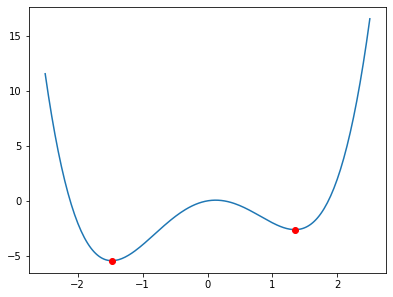

In [ ]:
import numpy as np
from scipy import optimize
import matplotlib.pyplot as plt
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import numpy as np
from scipy import optimize
import matplotlib.pyplot as plt


def f(x):
    return x ** 4 - 4 * x ** 2 + x


x = np.linspace(-2.5, 2.5, 200)
plt.plot(x, f(x))
for a, b in [(-2, 0), (0, 2)]:
    e = optimize.minimize_scalar(f, bounds=(a, b))
    print(round(e.x, 4), round(e.fun, 4))
    plt.plot(e.x, e.fun, 'ro')
plt.show()
```

</details>

#### Aufgabe 3.9

Was wird ausgegeben? Überlege zuerst, was ausgegeben wird. Führe dann die Zelle aus und vergleiche.

In [ ]:
from scipy import optimize


def f(x):
    return (x - 3) ** 2 + 1


e = optimize.minimize_scalar(f, bounds=(0, 10))
print(round(e.x, 2), round(e.fun, 2))

<details>
<summary>Lösung anzeigen (erst selbst überlegen!)</summary>

**Ausgabe:**
```
3.0 1.0
```

`(x - 3)²` ist nie negativ und genau bei `x = 3` gleich 0. Dort ist `f` am kleinsten, mit dem Wert `0 + 1 = 1`.
Gerundet ergibt sich `3.0 1.0`.

</details>

#### Aufgabe 3.10

Was wird ausgegeben? Überlege zuerst, was ausgegeben wird. Führe dann die Zelle aus und vergleiche.

In [ ]:
from scipy import optimize


def f(x):
    return 2 * x + 1


e = optimize.minimize_scalar(f, bounds=(1, 4))
print(round(e.x, 2), round(e.fun, 2))

<details>
<summary>Lösung anzeigen (erst selbst überlegen!)</summary>

**Ausgabe:**
```
1.0 3.0
```

`f` ist eine steigende Gerade, hat also keinen Tiefpunkt. Im Bereich von 1 bis 4 ist sie am **linken Rand** am kleinsten:
`f(1) = 3`. `minimize_scalar()` landet deshalb (bis auf winzige Abweichungen) bei `x = 1`, gerundet `1.0 3.0`.

</details>

## 4. Extremwertaufgaben

#### Vorgehen

Bei einer **Extremwertaufgabe** wird eine Größe gesucht, die so groß oder so klein wie möglich ist.

1. Die Größe, die optimiert werden soll (die **Zielfunktion**), mit mehreren Variablen aufschreiben.
2. Mit der **Nebenbedingung** alle Variablen bis auf eine ersetzen.
3. Den sinnvollen Bereich für diese Variable bestimmen (z. B. Längen größer als 0).
4. Mit `minimize_scalar()` das Minimum (bzw. das Minimum von `-f`) suchen.

Beispiel: Ein Rechteck hat den Umfang 20 cm. Wann ist die Fläche am größten? Fläche `A = a · b`, Nebenbedingung `2a + 2b = 20`, also `b = 10 - a`.

In [ ]:
from scipy import optimize


def flaeche(a):
    b = 10 - a
    return a * b


def minus_flaeche(a):
    return -flaeche(a)


e = optimize.minimize_scalar(minus_flaeche, bounds=(0, 10))
print(round(e.x, 4), round(flaeche(e.x), 4))

#### Aufgabe 4.1

Aus einem 30 cm × 20 cm großen Karton wird eine oben offene Schachtel gefaltet. Dazu schneidet man an den Ecken Quadrate mit der Seitenlänge `x` heraus.
Das Volumen ist `V(x) = x · (30 - 2x) · (20 - 2x)`. Für welches `x` ist das Volumen am größten? Gib `x` und das Volumen auf 2 Nachkommastellen aus.

**Erwartete Ausgabe:**
```
3.92 1056.31
```

In [ ]:
from scipy import optimize
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
from scipy import optimize


def volumen(x):
    return x * (30 - 2 * x) * (20 - 2 * x)


def minus_volumen(x):
    return -volumen(x)


e = optimize.minimize_scalar(minus_volumen, bounds=(0, 10))
print(round(e.x, 2), round(volumen(e.x), 2))
```

</details>

#### Aufgabe 4.2

Mit 60 m Zaun soll an einem geraden Fluss ein rechteckiges Feld eingezäunt werden. An der Flussseite braucht man keinen Zaun.
Für die beiden Seiten senkrecht zum Fluss (je `x`) und die Seite parallel zum Fluss gilt `2x + y = 60`.
Bestimme `x`, `y` und die größte Fläche (2 Nachkommastellen).

**Erwartete Ausgabe:**
```
15.0 30.0 450.0
```

In [ ]:
from scipy import optimize
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
from scipy import optimize


def flaeche(x):
    y = 60 - 2 * x
    return x * y


def minus_flaeche(x):
    return -flaeche(x)


e = optimize.minimize_scalar(minus_flaeche, bounds=(0, 30))
x = e.x
print(round(x, 2), round(60 - 2 * x, 2), round(flaeche(x), 2))
```

</details>

#### Aufgabe 4.3

Eine zylinderförmige Dose soll 1 Liter (1000 cm³) fassen und dabei möglichst wenig Blech verbrauchen.
Für den Radius `r` ist die Höhe `h = 1000 / (π r²)` und die Oberfläche `O = 2πr² + 2πrh`. Bestimme `r`, `h` und `O` (2 Nachkommastellen)
für `r` zwischen 1 und 20.

**Erwartete Ausgabe:**
```
5.42 10.84 553.58
```

In [ ]:
import numpy as np
from scipy import optimize
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import numpy as np
from scipy import optimize


def hoehe(r):
    return 1000 / (np.pi * r ** 2)


def oberflaeche(r):
    return 2 * np.pi * r ** 2 + 2 * np.pi * r * hoehe(r)


e = optimize.minimize_scalar(oberflaeche, bounds=(1, 20))
print(round(e.x, 2), round(hoehe(e.x), 2), round(e.fun, 2))
```

</details>

#### Aufgabe 4.4

Unter dem Graphen von `f(x) = 9 - x²` liegt ein Rechteck mit zwei Ecken auf der x-Achse bei `-x` und `x` und den anderen beiden Ecken auf dem Graphen.
Seine Fläche ist `A(x) = 2x · f(x)`. Bestimme `x` und die größte Fläche für `x` zwischen 0 und 3 (4 Nachkommastellen).

**Erwartete Ausgabe:**
```
1.7321 20.7846
```

In [ ]:
from scipy import optimize
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
from scipy import optimize


def f(x):
    return 9 - x ** 2


def minus_flaeche(x):
    return -2 * x * f(x)


e = optimize.minimize_scalar(minus_flaeche, bounds=(0, 3))
print(round(e.x, 4), round(-e.fun, 4))
```

</details>

#### Aufgabe 4.5

Welcher Punkt auf dem Graphen von `f(x) = x²` liegt dem Punkt P(3|0) am nächsten? Minimiere den Abstand
`d(x) = √((x - 3)² + f(x)²)` für `x` zwischen -5 und 5. Gib den Punkt und den Abstand auf 4 Nachkommastellen aus.

**Erwartete Ausgabe:**
```
1.0 1.0 2.2361
```

In [ ]:
import numpy as np
from scipy import optimize
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import numpy as np
from scipy import optimize


def f(x):
    return x ** 2


def abstand(x):
    return np.sqrt((x - 3) ** 2 + f(x) ** 2)


e = optimize.minimize_scalar(abstand, bounds=(-5, 5))
print(round(e.x, 4), round(f(e.x), 4), round(e.fun, 4))
```

</details>

#### Aufgabe 4.6

Ein Getränkehersteller verkauft bei einem Preis von `p` Euro pro Flasche `m(p) = 5000 - 1500p` Flaschen. Die Herstellung kostet 0.50 € pro Flasche.
Der Gewinn ist `G(p) = (p - 0.5) · m(p)`. Bei welchem Preis ist der Gewinn am größten? Gib Preis und Gewinn auf 2 Nachkommastellen aus
(Preise zwischen 0.5 und 3).

**Erwartete Ausgabe:**
```
1.92 3010.42
```

In [ ]:
from scipy import optimize
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
from scipy import optimize


def gewinn(p):
    return (p - 0.5) * (5000 - 1500 * p)


def minus_gewinn(p):
    return -gewinn(p)


e = optimize.minimize_scalar(minus_gewinn, bounds=(0.5, 3))
print(round(e.x, 2), round(gewinn(e.x), 2))
```

</details>

#### Aufgabe 4.7

Ein Rettungsschwimmer steht am Strand 30 m von der Wasserlinie entfernt. Die Person im Wasser ist 40 m weiter seitlich und 20 m im Wasser.
Er läuft zuerst zum Punkt `x` an der Wasserlinie (5 m/s) und schwimmt dann (1.5 m/s). Die Zeit ist
`T(x) = √(30² + x²) / 5 + √(20² + (40 - x)²) / 1.5`. Bestimme `x` und die kürzeste Zeit für `x` zwischen 0 und 40 (2 Nachkommastellen).

**Erwartete Ausgabe:**
```
35.3 22.96
```

In [ ]:
import numpy as np
from scipy import optimize
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import numpy as np
from scipy import optimize


def zeit(x):
    return np.sqrt(30 ** 2 + x ** 2) / 5 + np.sqrt(20 ** 2 + (40 - x) ** 2) / 1.5


e = optimize.minimize_scalar(zeit, bounds=(0, 40))
print(round(e.x, 2), round(e.fun, 2))
```

</details>

#### Aufgabe 4.8

Zeichne für die Schachtel-Aufgabe (Karton 30 cm × 20 cm) den Graphen des Volumens `V(x) = x · (30 - 2x) · (20 - 2x)` für `x` von 0 bis 10 (200 Punkte).
Markiere das Maximum als roten Punkt und beschrifte die Achsen mit `x in cm` und `Volumen in cm³`.

**Erwartete Ausgabe:**

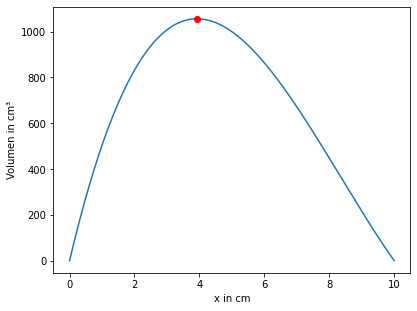

In [ ]:
import numpy as np
from scipy import optimize
import matplotlib.pyplot as plt
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import numpy as np
from scipy import optimize
import matplotlib.pyplot as plt


def volumen(x):
    return x * (30 - 2 * x) * (20 - 2 * x)


def minus_volumen(x):
    return -volumen(x)


e = optimize.minimize_scalar(minus_volumen, bounds=(0, 10))
x = np.linspace(0, 10, 200)
plt.plot(x, volumen(x))
plt.plot(e.x, volumen(e.x), 'ro')
plt.xlabel('x in cm')
plt.ylabel('Volumen in cm³')
plt.show()
```

</details>

#### Aufgabe 4.9

Was wird ausgegeben? Überlege zuerst, was ausgegeben wird. Führe dann die Zelle aus und vergleiche.

In [ ]:
from scipy import optimize


def flaeche(a):
    return a * (8 - a)


def minus_flaeche(a):
    return -flaeche(a)


e = optimize.minimize_scalar(minus_flaeche, bounds=(0, 8))
print(round(e.x, 2), round(flaeche(e.x), 2))

<details>
<summary>Lösung anzeigen (erst selbst überlegen!)</summary>

**Ausgabe:**
```
4.0 16.0
```

`flaeche(a) = a · (8 - a)` ist die Fläche eines Rechtecks mit den Seiten `a` und `8 - a` (Umfang 16). Am größten ist sie beim Quadrat
mit `a = 4`: `4 · 4 = 16`. Gesucht wird das Minimum von `-flaeche`, also das Maximum der Fläche. Ausgabe: `4.0 16.0`.

</details>

## 5. Integrale

#### `integrate.quad()`

Das Modul `scipy.integrate` berechnet Integrale. `integrate.quad(f, a, b)` (von *Quadratur*) berechnet das Integral von `f` von `a` bis `b`.
Anders als `np.trapezoid()` braucht es keine Messpunkte, sondern die Funktion selbst, und ist sehr genau.

Das Ergebnis ist ein **Tupel** aus zwei Zahlen: dem Wert des Integrals und einer Schätzung des Fehlers. Meist braucht man nur den Wert:
`wert, fehler = integrate.quad(f, a, b)` oder `integrate.quad(f, a, b)[0]`.

In [ ]:
from scipy import integrate


def f(x):
    return x ** 2


wert, fehler = integrate.quad(f, 0, 2)
print(wert)
print(fehler)
print(round(integrate.quad(f, 0, 2)[0], 6))

#### Integral und Fläche

Das Integral zählt Flächen **unterhalb** der x-Achse negativ. Die **Fläche** zwischen Graph und x-Achse berechnet man deshalb abschnittsweise:
Man teilt an den Nullstellen und addiert die Beträge (`abs()`) der Teilintegrale.

Die Fläche **zwischen zwei Graphen** `f` und `g` ist das Integral von `|f - g|`, auch hier abschnittsweise zwischen den Schnittstellen.

In [ ]:
from scipy import integrate


def f(x):
    return x ** 2 - 1


print(round(integrate.quad(f, 0, 2)[0], 6))
teil1 = integrate.quad(f, 0, 1)[0]
teil2 = integrate.quad(f, 1, 2)[0]
print(round(teil1, 6), round(teil2, 6))
print(round(abs(teil1) + abs(teil2), 6))

#### Unendliche Grenzen

Als Grenze darf auch `np.inf` (unendlich) stehen. So berechnet man **uneigentliche Integrale**, z. B. die Fläche unter `1/x²` von 1 bis ∞.
Das klappt natürlich nur, wenn die Fläche endlich ist.

In [ ]:
import numpy as np
from scipy import integrate


def f(x):
    return 1 / x ** 2


def g(x):
    return np.exp(-x)


print(round(integrate.quad(f, 1, np.inf)[0], 6))
print(round(integrate.quad(g, 0, np.inf)[0], 6))

#### Funktionen mit Parameter: `args=`

Hat die Funktion außer `x` noch einen **Parameter**, z. B. `f(x, a) = a · x²`, gibt man seinen Wert mit `args=(...)` an
(ein Tupel, deshalb bei einem Wert das Komma: `args=(3,)`). scipy ruft dann `f(x, 3)` auf.
`brentq()` und `minimize_scalar()` kennen `args=` genauso.

In [ ]:
from scipy import integrate


def f(x, a):
    return a * x ** 2


for a in [1, 2, 3]:
    print(a, round(integrate.quad(f, 0, 3, args=(a,))[0], 4))

#### Aufgabe 5.1

Berechne das Integral von `f(x) = 3x² + 2x` von 1 bis 3 (exakt: 34). Runde auf 6 Nachkommastellen.

**Erwartete Ausgabe:**
```
34.0
```

In [ ]:
from scipy import integrate
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
from scipy import integrate


def f(x):
    return 3 * x ** 2 + 2 * x


print(round(integrate.quad(f, 1, 3)[0], 6))
```

</details>

#### Aufgabe 5.2

Berechne das Integral von `f(x) = e^x` von 0 bis 1 und vergleiche mit `e - 1` (`np.e - 1`). Gib beides auf 6 Nachkommastellen aus.

**Erwartete Ausgabe:**
```
1.718282
1.718282
```

In [ ]:
import numpy as np
from scipy import integrate
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import numpy as np
from scipy import integrate


def f(x):
    return np.exp(x)


print(round(integrate.quad(f, 0, 1)[0], 6))
print(round(np.e - 1, 6))
```

</details>

#### Aufgabe 5.3

Gib den Wert und die Fehlerschätzung des Integrals von `f(x) = √x` von 0 bis 4 aus (Wert auf 6 Nachkommastellen, Fehler mit `:.1e`).

In [ ]:
import numpy as np
from scipy import integrate
# your code

<details>
<summary>Beispiellösung anzeigen (erst selbst probieren!)</summary>

```python
import numpy as np
from scipy import integrate


def f(x):
    return np.sqrt(x)


wert, fehler = integrate.quad(f, 0, 4)
print(round(wert, 6))
print(f'{fehler:.1e}')
```

</details>

#### Aufgabe 5.4

Die Funktion `f(x) = x² - 4` ist zwischen -2 und 2 negativ. Berechne das Integral von -3 bis 3 und die Fläche zwischen Graph und x-Achse
im selben Bereich (Teilintegrale an den Nullstellen -2 und 2). Runde auf 4 Nachkommastellen.

**Erwartete Ausgabe:**
```
-6.0
15.3333
```

In [ ]:
from scipy import integrate
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
from scipy import integrate


def f(x):
    return x ** 2 - 4


print(round(integrate.quad(f, -3, 3)[0], 4))
grenzen = [-3, -2, 2, 3]
flaeche = 0
for i in range(len(grenzen) - 1):
    flaeche += abs(integrate.quad(f, grenzen[i], grenzen[i + 1])[0])
print(round(flaeche, 4))
```

</details>

#### Aufgabe 5.5

Berechne die Fläche, die die Graphen von `f(x) = x` und `g(x) = x³` zwischen -1 und 1 einschließen. Sie schneiden sich bei -1, 0 und 1.
Runde auf 4 Nachkommastellen.

**Erwartete Ausgabe:**
```
0.5
```

In [ ]:
from scipy import integrate
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
from scipy import integrate


def d(x):
    return x - x ** 3


teil1 = integrate.quad(d, -1, 0)[0]
teil2 = integrate.quad(d, 0, 1)[0]
print(round(abs(teil1) + abs(teil2), 4))
```

</details>

#### Aufgabe 5.6

Berechne die Fläche, die die Graphen von `f(x) = cos(x)` und `g(x) = x² - 1` einschließen. Bestimme dazu zuerst die Schnittstellen mit `brentq()`
in den Intervallen [-2, -1] und [1, 2] und integriere `f - g` dazwischen. Gib die Schnittstellen und die Fläche auf 4 Nachkommastellen aus.

**Erwartete Ausgabe:**
```
-1.1765 1.1765
3.1139
```

In [ ]:
import numpy as np
from scipy import optimize, integrate
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import numpy as np
from scipy import optimize, integrate


def d(x):
    return np.cos(x) - (x ** 2 - 1)


x1 = optimize.brentq(d, -2, -1)
x2 = optimize.brentq(d, 1, 2)
print(round(x1, 4), round(x2, 4))
print(round(integrate.quad(d, x1, x2)[0], 4))
```

</details>

#### Aufgabe 5.7

Der **Mittelwert** einer Funktion auf dem Intervall [a, b] ist das Integral geteilt durch `b - a`. Die Temperatur an einem Tag
(in °C, `t` in Stunden) ist `T(t) = 12 - 6 cos(π t / 12)`. Berechne die mittlere Temperatur von 6 bis 18 Uhr (2 Nachkommastellen).

**Erwartete Ausgabe:**
```
15.82
```

In [ ]:
import numpy as np
from scipy import integrate
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import numpy as np
from scipy import integrate


def temperatur(t):
    return 12 - 6 * np.cos(np.pi * t / 12)


print(round(integrate.quad(temperatur, 6, 18)[0] / (18 - 6), 2))
```

</details>

#### Aufgabe 5.8

Ein Auto bremst. Seine Geschwindigkeit in m/s ist `v(t) = 25 · e^(-0.4t)`. Der zurückgelegte Weg ist das Integral der Geschwindigkeit.
Berechne den Weg in den ersten 5 Sekunden und den Weg, bis es (theoretisch) steht (Grenze `np.inf`), jeweils auf 2 Nachkommastellen.

**Erwartete Ausgabe:**
```
54.04
62.5
```

In [ ]:
import numpy as np
from scipy import integrate
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import numpy as np
from scipy import integrate


def v(t):
    return 25 * np.exp(-0.4 * t)


print(round(integrate.quad(v, 0, 5)[0], 2))
print(round(integrate.quad(v, 0, np.inf)[0], 2))
```

</details>

#### Aufgabe 5.9

Prüfe, ob die Fläche unter `1/x` von 1 bis `b` beschränkt bleibt: Gib für `b` = 10, 100, 1000 und 10000 das Integral auf 4 Nachkommastellen aus.
Vergleiche mit dem Ergebnis für `1/x²`.

**Erwartete Ausgabe:**
```
10 2.3026 0.9
100 4.6052 0.99
1000 6.9078 0.999
10000 9.2103 0.9999
```

In [ ]:
from scipy import integrate
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
from scipy import integrate


def f(x):
    return 1 / x


def g(x):
    return 1 / x ** 2


for b in [10, 100, 1000, 10000]:
    print(b, round(integrate.quad(f, 1, b)[0], 4), round(integrate.quad(g, 1, b)[0], 4))
```

</details>

#### Aufgabe 5.10

Dreht man den Graphen von `f` zwischen `a` und `b` um die x-Achse, entsteht ein Rotationskörper mit dem Volumen `V = π · ∫ f(x)² dx`.
Berechne das Volumen für `f(x) = √x` von 0 bis 4 und für `f(x) = 2` von 0 bis 3 (ein Zylinder, zum Vergleich `π · 2² · 3`). Runde auf 4 Nachkommastellen.

**Erwartete Ausgabe:**
```
25.1327
37.6991
37.6991
```

In [ ]:
import numpy as np
from scipy import integrate
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import numpy as np
from scipy import integrate


def f(x):
    return np.sqrt(x)


def f_quadrat(x):
    return f(x) ** 2


def zwei_quadrat(x):
    return 2 ** 2


print(round(np.pi * integrate.quad(f_quadrat, 0, 4)[0], 4))
print(round(np.pi * integrate.quad(zwei_quadrat, 0, 3)[0], 4))
print(round(np.pi * 2 ** 2 * 3, 4))
```

</details>

#### Aufgabe 5.11

Für welche obere Grenze `b` ist das Integral von `f(x) = x²` von 0 bis `b` gleich 9? Schreibe eine Funktion `h(b)`, die das Integral
minus 9 berechnet, und bestimme ihre Nullstelle mit `brentq()` im Intervall von 1 bis 5 (4 Nachkommastellen).

**Erwartete Ausgabe:**
```
3.0
```

In [ ]:
from scipy import optimize, integrate
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
from scipy import optimize, integrate


def f(x):
    return x ** 2


def h(b):
    return integrate.quad(f, 0, b)[0] - 9


print(round(optimize.brentq(h, 1, 5), 4))
```

</details>

#### Aufgabe 5.12

Zeichne die Graphen von `f(x) = 4 - x²` (blau) und `g(x) = x + 2` (grün) für x von -3 bis 2 (200 Punkte) und färbe die Fläche zwischen
ihnen zwischen den Schnittstellen -2 und 1 hellgrau (`plt.fill_between(x2, f(x2), g(x2), color='lightgray')` mit 100 Punkten `x2` von -2 bis 1).
Gib die Fläche auf 4 Nachkommastellen aus.

**Erwartete Ausgabe:**
```
4.5
```

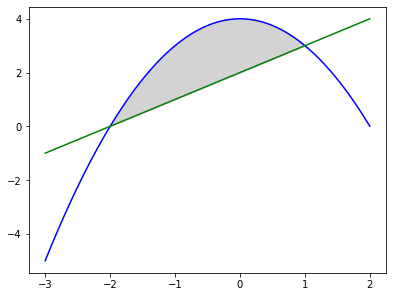

In [ ]:
import numpy as np
from scipy import integrate
import matplotlib.pyplot as plt
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import numpy as np
from scipy import integrate
import matplotlib.pyplot as plt


def f(x):
    return 4 - x ** 2


def g(x):
    return x + 2


def d(x):
    return f(x) - g(x)


print(round(integrate.quad(d, -2, 1)[0], 4))
x = np.linspace(-3, 2, 200)
x2 = np.linspace(-2, 1, 100)
plt.plot(x, f(x), color='blue')
plt.plot(x, g(x), color='green')
plt.fill_between(x2, f(x2), g(x2), color='lightgray')
plt.show()
```

</details>

#### Aufgabe 5.13

Was wird ausgegeben? Überlege zuerst, was ausgegeben wird. Führe dann die Zelle aus und vergleiche.

In [ ]:
from scipy import integrate


def f(x):
    return 2 * x


print(round(integrate.quad(f, 0, 3)[0], 4))
print(round(integrate.quad(f, -1, 3)[0], 4))

<details>
<summary>Lösung anzeigen (erst selbst überlegen!)</summary>

**Ausgabe:**
```
9.0
8.0
```

- Unter `f(x) = 2x` liegt von 0 bis 3 ein Dreieck mit Grundseite 3 und Höhe 6, also Fläche `3 · 6 / 2 = 9`.
- Von -1 bis 0 liegt ein Dreieck mit der Fläche `1 · 2 / 2 = 1` **unter** der x-Achse. Es zählt negativ, deshalb ist das Integral von -1 bis 3 gleich `9 - 1 = 8`.

</details>

#### Aufgabe 5.14

Was wird ausgegeben? Überlege zuerst, was ausgegeben wird. Führe dann die Zelle aus und vergleiche.

In [ ]:
from scipy import integrate


def f(x):
    return 5


ergebnis = integrate.quad(f, 1, 3)
print(len(ergebnis))
print(round(ergebnis[0], 4))

<details>
<summary>Lösung anzeigen (erst selbst überlegen!)</summary>

**Ausgabe:**
```
2
10.0
```

`quad()` gibt ein Tupel aus zwei Zahlen zurück (Wert und Fehlerschätzung), deshalb `2`.
Die konstante Funktion 5 ergibt von 1 bis 3 ein Rechteck mit der Fläche `5 · 2 = 10`.

</details>

## 6. Gemischte Übungen

#### Aufgabe 6.1

Eine Kurvendiskussion von `f(x) = x³ - 3x² - x + 2`: Gib die Nullstellen (Wertetabelle von -2 bis 4), den Hochpunkt (zwischen -1 und 1)
und den Tiefpunkt (zwischen 1 und 3) aus, alles auf 4 Nachkommastellen.

**Erwartete Ausgabe:**
```
Nullstelle: -0.8608
Nullstelle: 0.7459
Nullstelle: 3.1149
Hochpunkt: -0.1547 2.0792
Tiefpunkt: 2.1547 -4.0792
```

In [ ]:
import numpy as np
from scipy import optimize
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import numpy as np
from scipy import optimize


def f(x):
    return x ** 3 - 3 * x ** 2 - x + 2


def minus_f(x):
    return -f(x)


x = np.arange(-2, 5)
y = f(x)
for i in range(len(x) - 1):
    if y[i] * y[i + 1] < 0:
        print('Nullstelle:', round(optimize.brentq(f, x[i], x[i + 1]), 4))
hoch = optimize.minimize_scalar(minus_f, bounds=(-1, 1))
print('Hochpunkt:', round(hoch.x, 4), round(f(hoch.x), 4))
tief = optimize.minimize_scalar(f, bounds=(1, 3))
print('Tiefpunkt:', round(tief.x, 4), round(tief.fun, 4))
```

</details>

#### Aufgabe 6.2

Ein Medikament wird eingenommen. Die Konzentration im Blut (in mg/l, `t` in Stunden) ist `c(t) = 20 · (e^(-0.2t) - e^(-1.2t))`.
Gib aus: den Zeitpunkt und die Höhe der größten Konzentration (Bereich 0 bis 10), den Zeitpunkt, ab dem die Konzentration unter 2 mg/l fällt
(zwischen 5 und 30), und die mittlere Konzentration in den ersten 12 Stunden. Runde alles auf 2 Nachkommastellen.

**Erwartete Ausgabe:**
```
1.79 11.65
11.51
6.19
```

In [ ]:
import numpy as np
from scipy import optimize, integrate
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import numpy as np
from scipy import optimize, integrate


def c(t):
    return 20 * (np.exp(-0.2 * t) - np.exp(-1.2 * t))


def minus_c(t):
    return -c(t)


def h(t):
    return c(t) - 2


e = optimize.minimize_scalar(minus_c, bounds=(0, 10))
print(round(e.x, 2), round(c(e.x), 2))
print(round(optimize.brentq(h, 5, 30), 2))
print(round(integrate.quad(c, 0, 12)[0] / 12, 2))
```

</details>

#### Aufgabe 6.3

Für welchen Wert von `a` schließt die Parabel `f(x) = a · x · (4 - x)` mit der x-Achse zwischen 0 und 4 genau die Fläche 16 ein?
Schreibe `f(x, a)` und eine Funktion `h(a)`, die das Integral von 0 bis 4 (mit `args=`) minus 16 berechnet, und löse `h(a) = 0`
mit `brentq()` im Intervall von 0.1 bis 10 (4 Nachkommastellen).

**Erwartete Ausgabe:**
```
1.5
```

In [ ]:
from scipy import optimize, integrate
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
from scipy import optimize, integrate


def f(x, a):
    return a * x * (4 - x)


def h(a):
    return integrate.quad(f, 0, 4, args=(a,))[0] - 16


print(round(optimize.brentq(h, 0.1, 10), 4))
```

</details>

#### Aufgabe 6.4

Ein Tunnel hat im Querschnitt die Form der Parabel `f(x) = 6 - 1.5x²` über der x-Achse. Berechne die Breite am Boden (Nullstellen),
die Querschnittsfläche und die Breite in 4 m Höhe (Schnittstellen mit `y = 4`). Runde auf 2 Nachkommastellen.

**Erwartete Ausgabe:**
```
4.0
16.0
2.31
```

In [ ]:
from scipy import optimize, integrate
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
from scipy import optimize, integrate


def f(x):
    return 6 - 1.5 * x ** 2


def h(x):
    return f(x) - 4


x1 = optimize.brentq(f, -3, 0)
x2 = optimize.brentq(f, 0, 3)
print(round(x2 - x1, 2))
print(round(integrate.quad(f, x1, x2)[0], 2))
print(round(optimize.brentq(h, 0, 2) - optimize.brentq(h, -2, 0), 2))
```

</details>

#### Aufgabe 6.5

Welche Tangente an den Graphen von `f(x) = x²` geht durch den Punkt P(1|-3)? Die Tangente an der Stelle `u` hat die Gleichung
`y = 2u(x - u) + u²`. Sie geht durch P, wenn `2u(1 - u) + u² = -3` gilt. Bestimme beide Lösungen `u` (Intervalle [-3, 0] und [0, 5])
und gib jeweils `u` und die Steigung `2u` auf 4 Nachkommastellen aus.

**Erwartete Ausgabe:**
```
-1.0 -2.0
3.0 6.0
```

In [ ]:
from scipy import optimize
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
from scipy import optimize


def h(u):
    return 2 * u * (1 - u) + u ** 2 + 3


for a, b in [(-3, 0), (0, 5)]:
    u = optimize.brentq(h, a, b)
    print(round(u, 4), round(2 * u, 4))
```

</details>

#### Aufgabe 6.6

Zeichne den Graphen von `f(x) = x · e^(-x/2)` für x von 0 bis 10 (200 Punkte). Markiere den Hochpunkt (zwischen 0 und 10) als roten Punkt
und färbe die Fläche unter dem Graphen von 0 bis 10 hellblau (`color='lightblue'`). Gib den Hochpunkt und die Fläche auf 4 Nachkommastellen aus.

**Erwartete Ausgabe:**
```
2.0 0.7358
3.8383
```

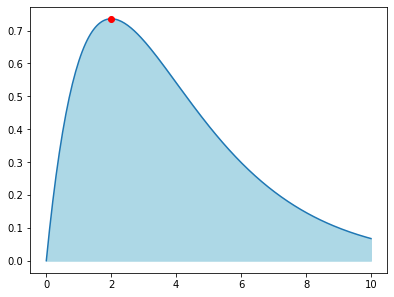

In [ ]:
import numpy as np
from scipy import optimize, integrate
import matplotlib.pyplot as plt
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import numpy as np
from scipy import optimize, integrate
import matplotlib.pyplot as plt


def f(x):
    return x * np.exp(-x / 2)


def minus_f(x):
    return -f(x)


e = optimize.minimize_scalar(minus_f, bounds=(0, 10))
print(round(e.x, 4), round(f(e.x), 4))
print(round(integrate.quad(f, 0, 10)[0], 4))
x = np.linspace(0, 10, 200)
plt.plot(x, f(x))
plt.fill_between(x, f(x), color='lightblue')
plt.plot(e.x, f(e.x), 'ro')
plt.show()
```

</details>

#### Aufgabe 6.7

Erfinde eine eigene Funktion und führe für sie eine kleine Kurvendiskussion durch: Nullstellen, Extremstellen und die Fläche zwischen zwei Nullstellen.
Zeichne den Graphen mit den markierten Punkten.

In [ ]:
import numpy as np
from scipy import optimize, integrate
import matplotlib.pyplot as plt
# your code

<details>
<summary>Beispiellösung anzeigen (erst selbst probieren!)</summary>

```python
import numpy as np
from scipy import optimize, integrate
import matplotlib.pyplot as plt


def f(x):
    return -x ** 3 + 3 * x ** 2


def minus_f(x):
    return -f(x)


x0 = optimize.brentq(f, 2, 4)
hoch = optimize.minimize_scalar(minus_f, bounds=(1, 3))
print('Nullstellen:', 0, round(x0, 4))
print('Hochpunkt:', round(hoch.x, 4), round(f(hoch.x), 4))
print('Fläche:', round(integrate.quad(f, 0, x0)[0], 4))
x = np.linspace(-1, 4, 200)
plt.plot(x, f(x))
plt.axhline(0, color='black')
plt.plot([0, x0], [0, 0], 'ro')
plt.plot(hoch.x, f(hoch.x), 'go')
plt.show()
```

</details>